In [2]:
import pandas as pd
import numpy as np

In [8]:
df = pd.read_csv(r"C:\Users\gadgat\Downloads\social_media_engagement_5000 (1).csv")

In [9]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [11]:
df.shape

(5000, 19)

In [14]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [16]:
#data cleanning
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [17]:
df.isnull().sum().sum()

np.int64(900)

In [18]:
df.isna().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [19]:
# missing value
df_drop = df.dropna()

print("Original dataset:", df.shape)
print("After removing missing values:", df_drop.shape)

Original dataset: (5000, 19)
After removing missing values: (4162, 19)


In [20]:
df['likes'] = df['likes'].fillna(0)

In [21]:
df['likes'] = df['likes'].fillna(df['likes'].median())

In [22]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])

In [23]:
df = df.ffill()

In [24]:
df = df.bfill()

In [25]:
df.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

In [26]:
# dupilcate value
df.duplicated().sum()


np.int64(0)

In [27]:
df[df.duplicated()]

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate


In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
# data formatting

df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [30]:
df['gender'] = df['gender'].str.lower().str.strip()

In [31]:
df['gender'].unique()

<ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str

In [32]:
print(df[['likes', 'comments', 'shares']].describe())

              likes     comments       shares
count   5000.000000  5000.000000  5000.000000
mean    9803.832400  1503.504600  1002.058600
std     5957.295788   869.443836   579.106821
min        0.000000     0.000000     0.000000
25%     4625.750000   760.000000   497.750000
50%     9776.000000  1498.000000  1010.500000
75%    14959.000000  2258.000000  1500.250000
max    19998.000000  2999.000000  1999.000000


In [33]:
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0


In [34]:
#Feature Cleaning
df['hashtag_count'] = df['hashtags'].fillna('').str.count('#')

In [35]:
df[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [36]:
df['sentiment'] = df['sentiment'].str.lower().str.strip()

In [37]:
df['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [38]:
df['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [39]:
df['sentiment'].value_counts()

sentiment
positive    2434
neutral     1575
negative     991
Name: count, dtype: int64

In [40]:
#Data Exploration using Pandas
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1


In [41]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,USA,273595,text,travel,13487.0,2734.0,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [42]:
df.shape

(5000, 20)

In [43]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               5000 non-null   float64
 2   gender            5000 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             5000 non-null   float64
 8   comments          5000 non-null   float64
 9   shares            5000 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         5000 non-null   str    
 17  hashta

In [45]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
hashtag_count         int64
dtype: object

In [46]:
df.select_dtypes(include=np.number).columns

Index(['user_id', 'age', 'post_id', 'likes', 'comments', 'shares',
       'watch_time_sec', 'impression_count', 'follower_count',
       'engagement_rate', 'hashtag_count'],
      dtype='str')

In [47]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.539600,548042.909000,9803.832400,1503.504600,1002.058600,4014.503200,50013.732800,393698.224800,0.964356,1.998600
std,26090.370121,14.949874,260646.957267,5957.295788,869.443836,579.106821,2308.096459,28844.939104,230927.884535,5.318029,0.812853
min,10055.000000,13.000000,100068.000000,0.000000,0.000000,0.000000,0.000000,105.000000,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,4625.750000,760.000000,497.750000,2017.750000,24988.250000,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,9776.000000,1498.000000,1010.500000,4034.500000,49934.500000,388982.000000,0.253896,2.000000
75%,77180.500000,52.000000,771574.500000,14959.000000,2258.000000,1500.250000,6020.250000,74662.250000,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,799533.000000,191.504348,3.000000


In [48]:
df.describe(include='all')

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000,5000,5000,5000,5000.000000,5000.000000
unique,NaN,NaN,3,10,NaN,4,8,NaN,NaN,NaN,NaN,NaN,729,NaN,2,3,3,761,NaN,NaN
top,NaN,NaN,male,India,NaN,reel,fitness,NaN,NaN,NaN,NaN,NaN,26-12-2023,NaN,False,mobile,positive,#tech,NaN,NaN
freq,NaN,NaN,1849,535,NaN,1283,675,NaN,NaN,NaN,NaN,NaN,16,NaN,4517,1684,2434,201,NaN,NaN
mean,54561.890800,38.539600,NaN,NaN,548042.909000,NaN,NaN,9803.832400,1503.504600,1002.058600,4014.503200,50013.732800,NaN,393698.224800,NaN,NaN,NaN,NaN,0.964356,1.998600
std,26090.370121,14.949874,NaN,NaN,260646.957267,NaN,NaN,5957.295788,869.443836,579.106821,2308.096459,28844.939104,NaN,230927.884535,NaN,NaN,NaN,NaN,5.318029,0.812853
min,10055.000000,13.000000,NaN,NaN,100068.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,105.000000,NaN,87.000000,NaN,NaN,NaN,NaN,0.006363,1.000000
25%,32309.500000,26.000000,NaN,NaN,322543.500000,NaN,NaN,4625.750000,760.000000,497.750000,2017.750000,24988.250000,NaN,194480.000000,NaN,NaN,NaN,NaN,0.145781,1.000000
50%,54374.500000,38.000000,NaN,NaN,548077.500000,NaN,NaN,9776.000000,1498.000000,1010.500000,4034.500000,49934.500000,NaN,388982.000000,NaN,NaN,NaN,NaN,0.253896,2.000000
75%,77180.500000,52.000000,NaN,NaN,771574.500000,NaN,NaN,14959.000000,2258.000000,1500.250000,6020.250000,74662.250000,NaN,589744.250000,NaN,NaN,NaN,NaN,0.504794,3.000000


In [49]:
df[['likes', 'comments', 'shares']].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.000000
mean,9803.832400,1503.504600,1002.058600
std,5957.295788,869.443836,579.106821
min,0.000000,0.000000,0.000000
25%,4625.750000,760.000000,497.750000
50%,9776.000000,1498.000000,1010.500000
75%,14959.000000,2258.000000,1500.250000
max,19998.000000,2999.000000,1999.000000


In [50]:
df['gender'].value_counts()

gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

In [52]:
df['post_type'].value_counts()

post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

In [53]:
df['country'].unique()

<ArrowStringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str

In [54]:
df['sentiment'].unique()

<ArrowStringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [55]:
df['country'].nunique()

10

In [56]:
df['post_type'].nunique()

4

In [57]:
categorical_columns = ['gender', 'country', 'post_type', 'sentiment']

for col in categorical_columns:
    print("\nColumn:", col)
    print("Unique values:", df[col].unique())
    print("Number of unique values:", df[col].nunique())
    print("Category counts:")
    print(df[col].value_counts())


Column: gender
Unique values: <ArrowStringArray>
['female', 'male', 'other']
Length: 3, dtype: str
Number of unique values: 3
Category counts:
gender
male      1849
other     1581
female    1570
Name: count, dtype: int64

Column: country
Unique values: <ArrowStringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str
Number of unique values: 10
Category counts:
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64

Column: post_type
Unique values: <ArrowStringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
Number of unique values: 4
Category counts:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Column: sentiment
Unique values: <ArrowStringArray>
['negative', 'positive',

In [58]:
numeric_df = df.select_dtypes(include=np.number)

In [59]:
correlation_matrix = numeric_df.corr()

In [60]:
correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.009584,0.020051,0.021377,-0.034024,0.013534,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.009584,1.000000,-0.019619,-0.039298,-0.004271,0.015298,0.005580,0.011541,-0.027005,0.008356,0.006120
post_id,0.020051,-0.019619,1.000000,0.010650,-0.008969,0.001371,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.021377,-0.039298,0.010650,1.000000,-0.017960,0.007193,0.002865,0.002746,-0.023670,0.094458,-0.003436
comments,-0.034024,-0.004271,-0.008969,-0.017960,1.000000,0.007534,-0.016789,-0.008705,-0.017114,0.000151,-0.018355
shares,0.013534,0.015298,0.001371,0.007193,0.007534,1.000000,0.016494,-0.005523,-0.007200,0.021675,0.010512
watch_time_sec,-0.016847,0.005580,0.018374,0.002865,-0.016789,0.016494,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.011541,-0.007709,0.002746,-0.008705,-0.005523,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.027005,-0.002844,-0.023670,-0.017114,-0.007200,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008356,0.010139,0.094458,0.000151,0.021675,-0.001148,-0.232226,0.002292,1.000000,0.005319


In [63]:
df.groupby('post_type')['likes'].mean()

post_type
image    9845.542101
reel     9683.361652
text     9783.590361
video    9908.120816
Name: likes, dtype: float64

In [66]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [67]:
df.groupby('post_type')['likes'].mean()

post_type
image    9845.542101
reel     9683.361652
text     9783.590361
video    9908.120816
Name: likes, dtype: float64

In [68]:
df.groupby('country')['impression_count'].sum()

country
Australia    23834767
Brazil       24793360
Canada       24984716
France       25656926
Germany      23816649
India        28067377
Japan        23418816
UAE          24610992
UK           25201861
USA          25683200
Name: impression_count, dtype: int64

In [69]:
df.groupby('country')['impression_count'].mean()

country
Australia    48346.383367
Brazil       49193.174603
Canada       48703.150097
France       51727.673387
Germany      48605.406122
India        52462.386916
Japan        49616.135593
UAE          48928.413519
UK           51119.393509
USA          51263.872255
Name: impression_count, dtype: float64

In [70]:
df.groupby('sentiment')['engagement_rate'].mean()

sentiment
negative    1.015169
neutral     0.973683
positive    0.937632
Name: engagement_rate, dtype: float64

In [71]:
df.groupby('device_type')['watch_time_sec'].mean()

device_type
desktop    3974.792521
mobile     4087.830760
tablet     3979.736429
Name: watch_time_sec, dtype: float64

In [72]:
df.groupby('post_type')['likes'].mean().sort_values(ascending=False)

post_type
video    9908.120816
image    9845.542101
text     9783.590361
reel     9683.361652
Name: likes, dtype: float64

In [73]:
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

In [74]:
df[['likes', 'comments', 'shares', 'engagement_score']].head(10)

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0
5,12535.0,1790.0,99.0,14424.0
6,11703.0,2276.0,1465.0,15444.0
7,9611.0,146.0,424.0,10181.0
8,0.0,2379.0,1897.0,4276.0
9,14106.0,2480.0,1053.0,17639.0


In [75]:
df['engagement_score'].mean()

np.float64(12309.3956)

In [76]:
df.groupby('post_type')['engagement_score'].mean()

post_type
image    12388.643144
reel     12173.744349
text     12290.127711
video    12390.381224
Name: engagement_score, dtype: float64

In [77]:
df.groupby('country')['engagement_score'].mean()

country
Australia    12466.837728
Brazil       12155.343254
Canada       12361.161793
France       12640.479839
Germany      12161.542857
India        12026.190654
Japan        12365.599576
UAE          12490.872763
UK           12125.645030
USA          12321.351297
Name: engagement_score, dtype: float64

In [78]:
df.groupby('sentiment')['engagement_score'].mean()

sentiment
negative    12385.927346
neutral     12210.008889
positive    12342.547247
Name: engagement_score, dtype: float64

In [79]:
df.groupby('post_type')[['likes', 'comments', 'shares', 'engagement_score']].mean()

,likes,comments,shares,engagement_score
post_type,,,,
image,9845.542101,1525.987169,1017.113873,12388.643144
reel,9683.361652,1507.982073,982.400624,12173.744349
text,9783.590361,1497.349398,1009.187952,12290.127711
video,9908.120816,1482.184490,1000.075918,12390.381224


In [80]:
df['engagement_score'] = df['likes'] + df['comments'] + df['shares']

In [81]:
df[['likes', 'comments', 'shares', 'engagement_score']].head()

,likes,comments,shares,engagement_score
0,7011.0,354.0,1157.0,8522.0
1,11750.0,2606.0,1807.0,16163.0
2,4862.0,344.0,955.0,6161.0
3,5350.0,1083.0,1049.0,7482.0
4,12682.0,2735.0,1300.0,16717.0


In [82]:
df['hashtag_count'] = df['hashtags'].fillna('').str.count('#')

In [83]:
df[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [84]:
df.groupby('post_type')['engagement_score'].mean()

post_type
image    12388.643144
reel     12173.744349
text     12290.127711
video    12390.381224
Name: engagement_score, dtype: float64

In [85]:
df.groupby('country')['engagement_score'].mean()

country
Australia    12466.837728
Brazil       12155.343254
Canada       12361.161793
France       12640.479839
Germany      12161.542857
India        12026.190654
Japan        12365.599576
UAE          12490.872763
UK           12125.645030
USA          12321.351297
Name: engagement_score, dtype: float64

In [86]:
df.groupby('post_type')[['likes', 'comments', 'shares']].mean()

,likes,comments,shares
post_type,,,
image,9845.542101,1525.987169,1017.113873
reel,9683.361652,1507.982073,982.400624
text,9783.590361,1497.349398,1009.187952
video,9908.120816,1482.184490,1000.075918


In [87]:
df1 = df.iloc[:2500]
df2 = df.iloc[2500:]

combined_df = pd.concat([df1, df2], ignore_index=True)

In [88]:
combined_df.shape

(5000, 21)

In [90]:
# Statistical Analysis 

columns = ['likes', 'comments', 'shares',
           'watch_time_sec', 'engagement_rate',
           'follower_count']

df[columns].mean()


likes                9803.832400
comments             1503.504600
shares               1002.058600
watch_time_sec       4014.503200
engagement_rate         0.964356
follower_count     393698.224800
dtype: float64

In [91]:
df[columns].median()

likes                9776.000000
comments             1498.000000
shares               1010.500000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

In [92]:
df[columns].mode().iloc[0]

likes                   0.000000
comments             2934.000000
shares                397.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [93]:
df[columns].std()

likes                5957.295788
comments              869.443836
shares                579.106821
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [94]:
df[columns].var()

likes              3.548937e+07
comments           7.559326e+05
shares             3.353647e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [95]:
df[columns].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,4625.75,760.0,497.75,2017.75,0.145781,194480.00
0.50,9776.00,1498.0,1010.50,4034.50,0.253896,388982.00
0.75,14959.00,2258.0,1500.25,6020.25,0.504794,589744.25


In [96]:
df[columns].median()

likes                9776.000000
comments             1498.000000
shares               1010.500000
watch_time_sec       4034.500000
engagement_rate         0.253896
follower_count     388982.000000
dtype: float64

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\gadgat\Downloads\social_media_engagement_5000 (1).csv")

In [5]:
columns = ['likes', 'comments', 'shares',
           'watch_time_sec', 'engagement_rate',
           'follower_count']

In [6]:
df[columns].mode().iloc[0]

likes                6486.000000
comments             2934.000000
shares                138.000000
watch_time_sec        916.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64

In [7]:
df[columns].std()

likes                5789.819252
comments              869.537889
shares                579.615158
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [8]:
df[columns].var()

likes              3.352201e+07
comments           7.560961e+05
shares             3.359537e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [9]:
df[columns].std()

likes                5789.819252
comments              869.537889
shares                579.615158
watch_time_sec       2308.096459
engagement_rate         5.318029
follower_count     230927.884535
dtype: float64

In [10]:
df[columns].var()

likes              3.352201e+07
comments           7.560961e+05
shares             3.359537e+05
watch_time_sec     5.327309e+06
engagement_rate    2.828143e+01
follower_count     5.332769e+10
dtype: float64

In [11]:
df[columns].quantile([0.25, 0.50, 0.75])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5068.5,760.0,498.0,2017.75,0.145781,194480.00
0.50,10105.5,1497.0,1012.0,4034.50,0.253896,388982.00
0.75,15115.0,2256.0,1501.0,6020.25,0.504794,589744.25


In [14]:
#Data Visualization.
import matplotlib.pyplot as plt

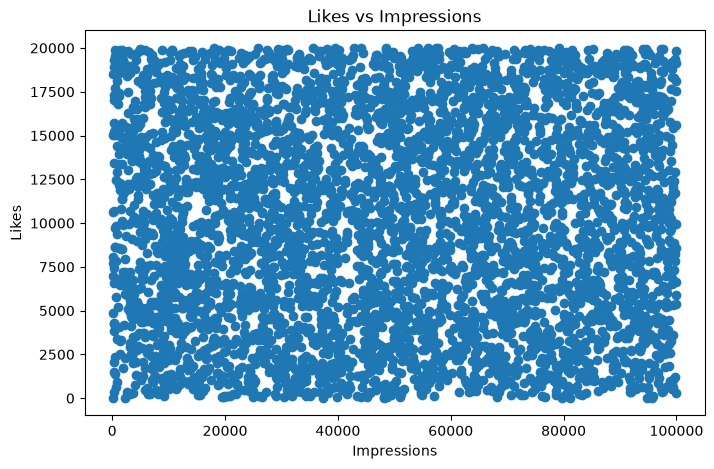

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df['impression_count'], df['likes'])

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

In [16]:
df['engagement_score'] = (
    df['likes'] + df['comments'] + df['shares']
)

In [17]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [18]:
daily_engagement = df.groupby(
    df['posted_at'].dt.date
)['engagement_score'].mean()

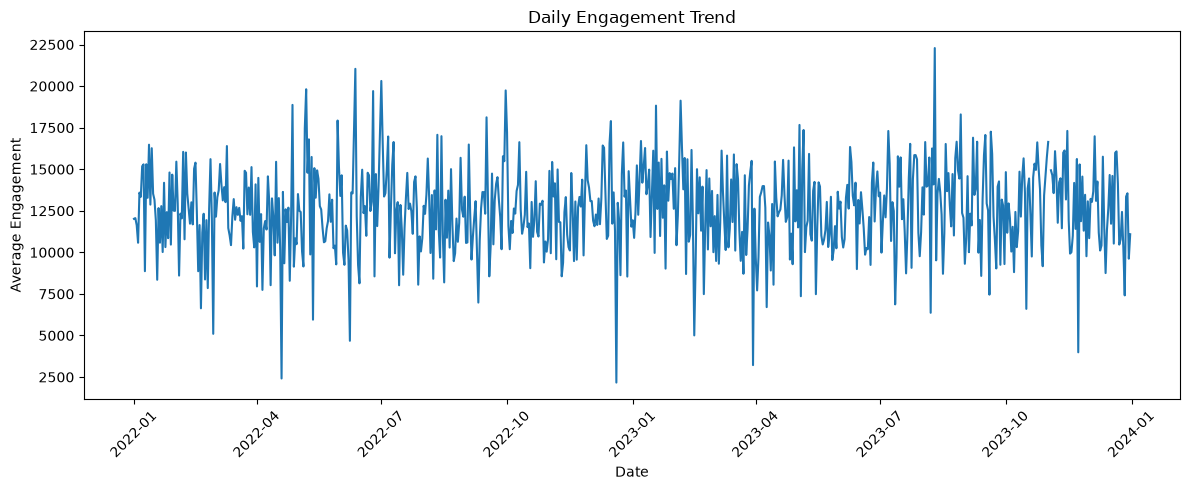

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel('Date')
plt.ylabel('Average Engagement')
plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
category_counts = df['post_category'].value_counts()

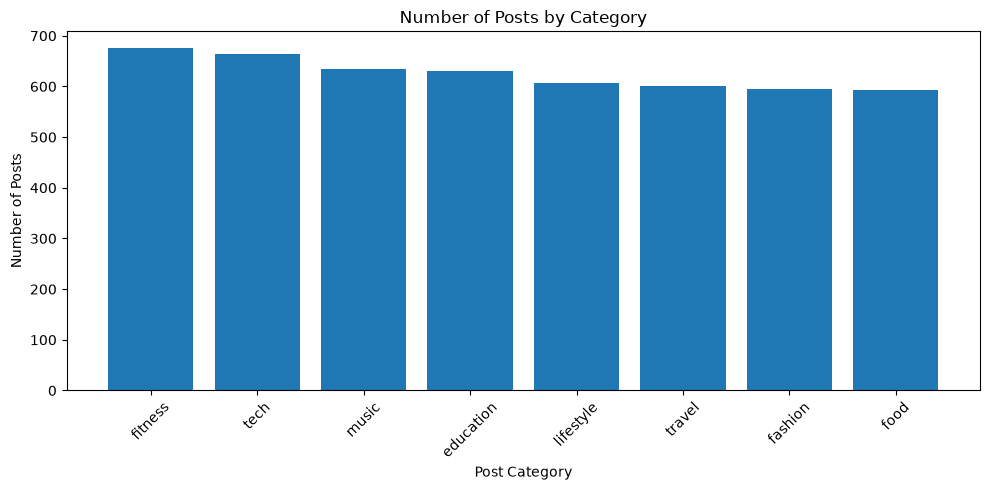

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(category_counts.index, category_counts.values)

plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
gender_counts = df['gender'].value_counts()

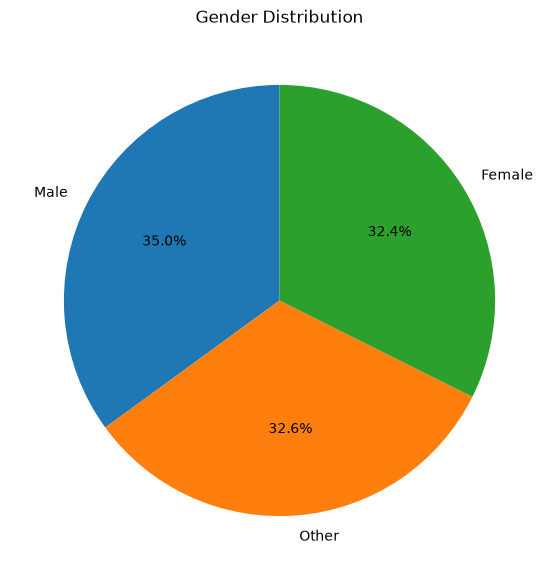

In [23]:
plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution')
plt.show()

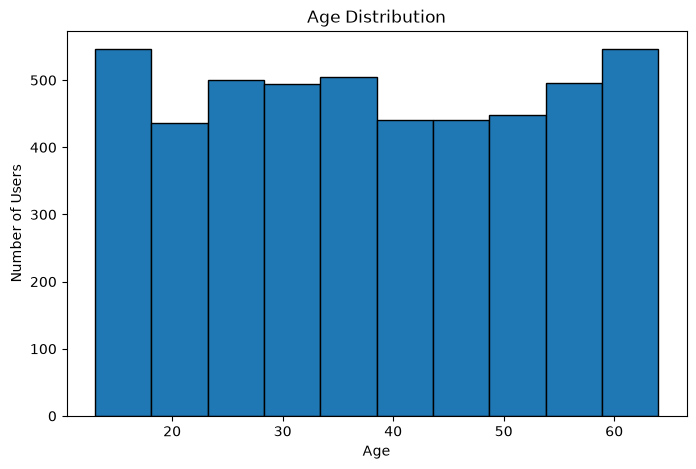

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(df['age'], bins=10, edgecolor='black')

plt.xlabel('Age')
plt.ylabel('Number of Users')
plt.title('Age Distribution')

plt.show()

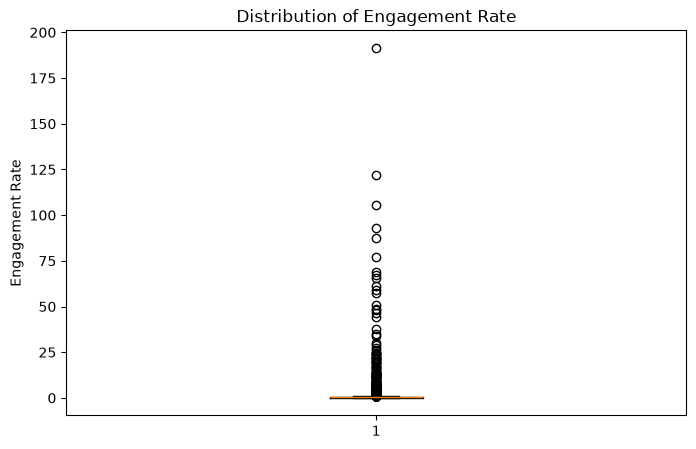

In [26]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['engagement_rate'].dropna())

plt.ylabel('Engagement Rate')
plt.title('Distribution of Engagement Rate')

plt.show()

In [27]:
import seaborn as sns

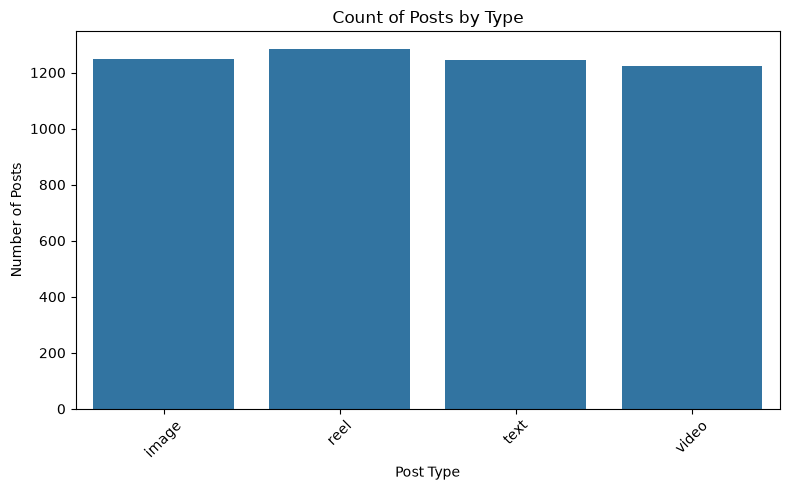

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='post_type')

plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Count of Posts by Type')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
avg_likes = df.groupby('post_category')['likes'].mean().reset_index()

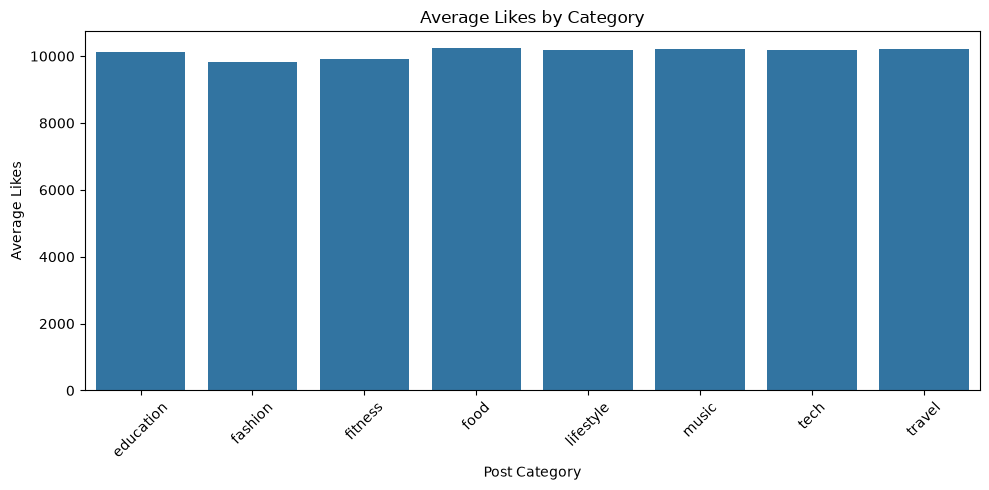

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(data=avg_likes, x='post_category', y='likes')

plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Category')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

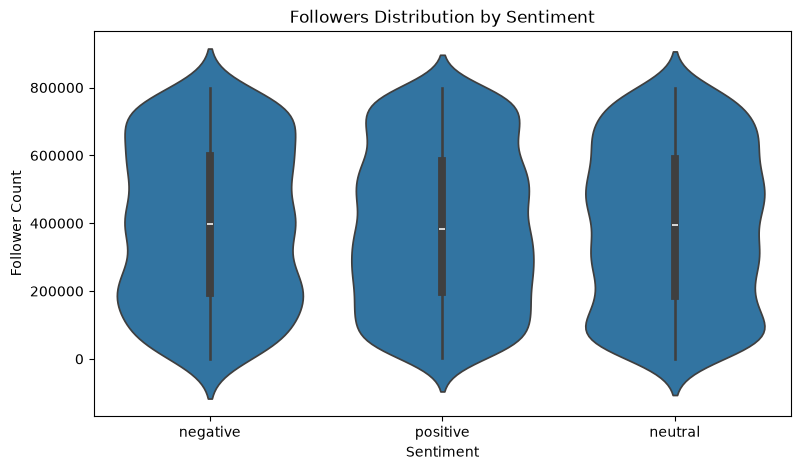

In [31]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.title('Followers Distribution by Sentiment')

plt.show()

In [32]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

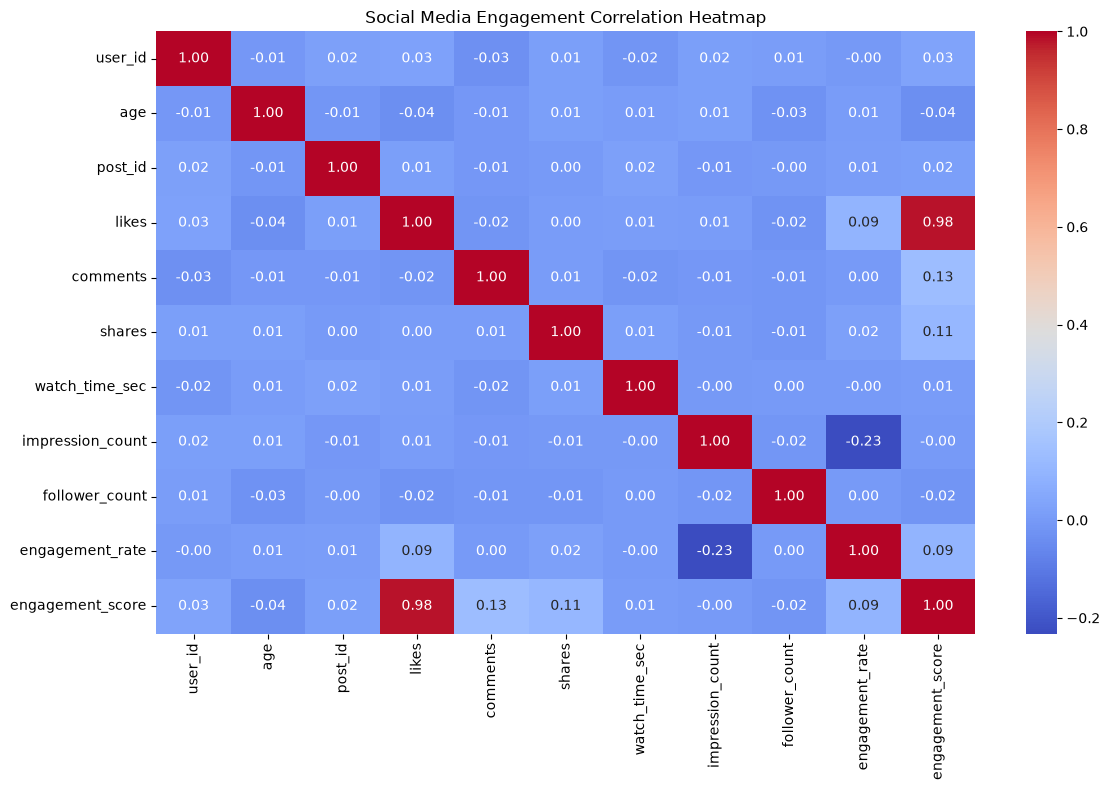

In [33]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Social Media Engagement Correlation Heatmap')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

sns.swarmplot(
    data=df,
    x='device_type',
    y='engagement_rate'
)

plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.title('Engagement Rate by Device Type')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\gadgat\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 68.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\gadgat\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 69.9% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\gadgat\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 69.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\gadgat\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 74.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
C:\Users\gadgat\anaconda3\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 75.6% of the p

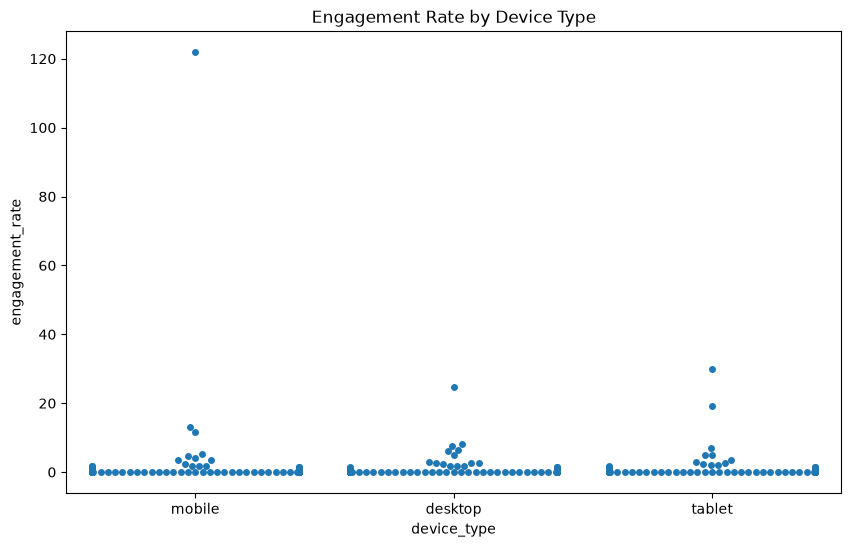

In [78]:
sample_df = df.sample(n=500, random_state=42)

plt.figure(figsize=(10, 6))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_rate'
)

plt.title('Engagement Rate by Device Type')
plt.show()

In [79]:
import plotly.express as px

In [ ]:
fig = px.scatter(
    df,
    x='impression_count',
    y='likes',
    color='post_type',
    title='Interactive Likes vs Impressions',
    labels={
        'impression_count': 'Impressions',
        'likes': 'Likes'
    }
)

fig.show()

In [74]:
#Content Performance
df.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False)

post_type
video    12658.675844
image    12627.062882
reel     12560.733850
text     12529.878199
Name: engagement_score, dtype: float64

In [73]:
df.groupby('post_category')['engagement_score'].mean().sort_values(ascending=False)

post_category
music        12896.741710
food         12656.661710
tech         12649.633117
lifestyle    12616.940109
travel       12595.420857
education    12594.467826
fitness      12483.886614
fashion      12249.938889
Name: engagement_score, dtype: float64

In [72]:
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64

In [71]:
print("Average Engagement by Post Type:")
print(df.groupby('post_type')['engagement_score'].mean().sort_values(ascending=False))

print("\nAverage Engagement by Category:")
print(df.groupby('post_category')['engagement_score'].mean().sort_values(ascending=False))

print("\nAverage Engagement Rate by Country:")
print(df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False))

Average Engagement by Post Type:
post_type
video    12658.675844
image    12627.062882
reel     12560.733850
text     12529.878199
Name: engagement_score, dtype: float64

Average Engagement by Category:
post_category
music        12896.741710
food         12656.661710
tech         12649.633117
lifestyle    12616.940109
travel       12595.420857
education    12594.467826
fitness      12483.886614
fashion      12249.938889
Name: engagement_score, dtype: float64

Average Engagement Rate by Country:
country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [70]:
df.groupby('age')['engagement_score'].mean()

age
13.0    12680.452055
14.0    13228.698925
15.0    12900.486486
16.0    12330.134146
17.0    14053.046512
18.0    12477.159091
19.0    11839.535714
20.0    13233.418919
21.0    12564.265823
22.0    12207.925000
23.0    12480.202703
24.0    13220.806122
25.0    13144.270000
26.0    11914.012500
27.0    12453.470588
28.0    11960.357143
29.0    13087.306122
30.0    12892.000000
31.0    12664.168831
32.0    13090.390805
33.0    13874.568182
34.0    12805.974359
35.0    12369.901961
36.0    13458.829787
37.0    11932.045455
38.0    13334.314815
39.0    13487.900000
40.0    11637.955556
41.0    12039.780220
42.0    12358.383562
43.0    12566.987500
44.0    12515.756410
45.0    12719.130952
46.0    12264.898734
47.0    11693.891566
48.0    12653.333333
49.0    14486.547619
50.0    13196.387500
51.0    12208.828283
52.0    12433.551282
53.0    11341.507246
54.0    12110.096154
55.0    11502.551724
56.0    12779.714286
57.0    12283.626374
58.0    11594.291139
59.0    11972.592105
60.0    1

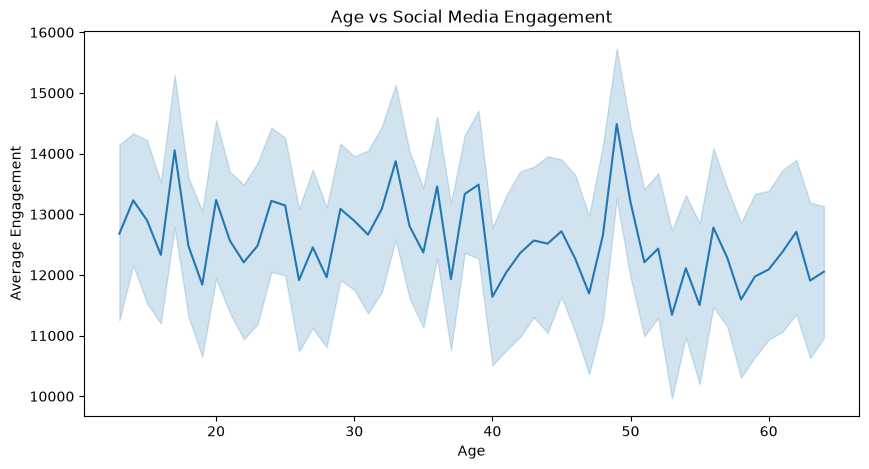

In [68]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=df,
    x='age',
    y='engagement_score'
)

plt.xlabel('Age')
plt.ylabel('Average Engagement')
plt.title('Age vs Social Media Engagement')

plt.show()







In [69]:
df.groupby('is_verified')['engagement_score'].mean()

is_verified
False    12617.413223
True     12379.117517
Name: engagement_score, dtype: float64

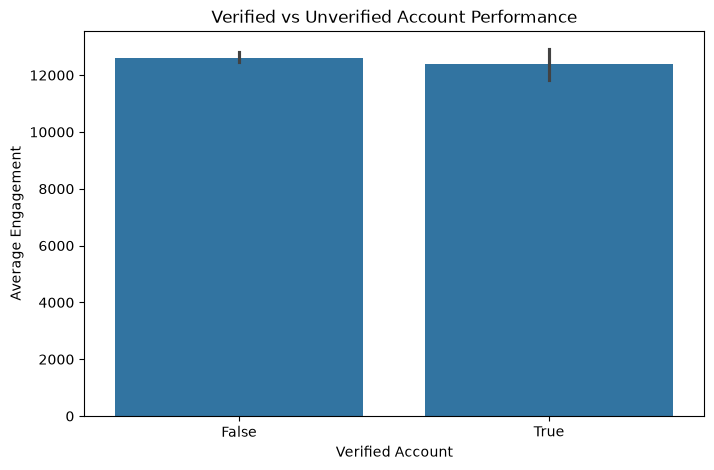

In [66]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='is_verified',
    y='engagement_score'
)

plt.xlabel('Verified Account')
plt.ylabel('Average Engagement')
plt.title('Verified vs Unverified Account Performance')

plt.show()

In [65]:


df.groupby('is_verified').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_score', 'mean')
)

,average_likes,average_comments,average_shares,average_engagement
is_verified,,,,
False,10138.207629,1505.777626,1001.264168,12617.413223
True,9817.985169,1468.814894,1015.234177,12379.117517


In [64]:
df['post_hour'] = df['posted_at'].dt.hour

In [63]:
df.groupby('post_hour')['impression_count'].mean().sort_values(ascending=False)

post_hour
0    50013.7328
Name: impression_count, dtype: float64

In [61]:
df['posted_at'] = pd.to_datetime(df['posted_at'], errors='coerce')

df['post_hour'] = df['posted_at'].dt.hour

In [60]:
df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64

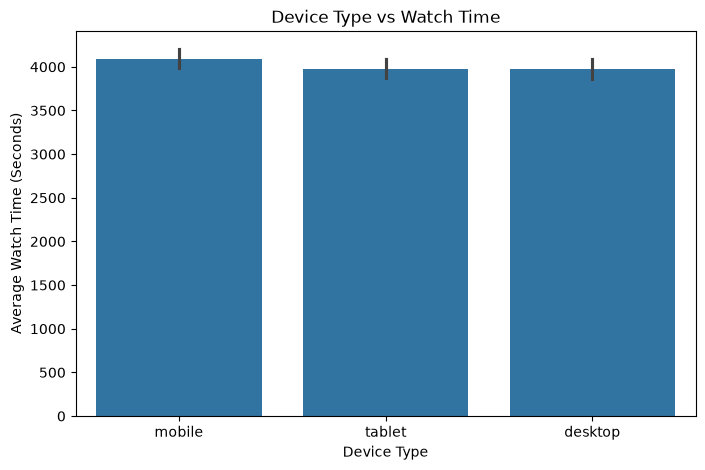

In [55]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='device_type',
    y='watch_time_sec'
)

plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (Seconds)')
plt.title('Device Type vs Watch Time')

plt.show()

In [54]:
df.groupby('device_type').agg(
    average_watch_time=('watch_time_sec', 'mean'),
    average_impressions=('impression_count', 'mean'),
    average_likes=('likes', 'mean')
)

,average_watch_time,average_impressions,average_likes
device_type,,,
desktop,3974.792521,50934.068758,10203.217364
mobile,4087.830760,49516.948931,10160.161271
tablet,3979.736429,49597.971049,9957.584988


In [53]:
df.groupby('sentiment')['engagement_score'].mean().sort_values(ascending=False)

sentiment
negative    12745.962670
positive    12593.029963
neutral     12459.355160
Name: engagement_score, dtype: float64

In [52]:
df.groupby('sentiment')[['likes', 'comments', 'shares']].mean()

,likes,comments,shares
sentiment,,,
negative,10211.406452,1516.584402,1007.186966
neutral,9917.785570,1529.270525,996.149966
positive,10158.542994,1481.890057,1001.503073


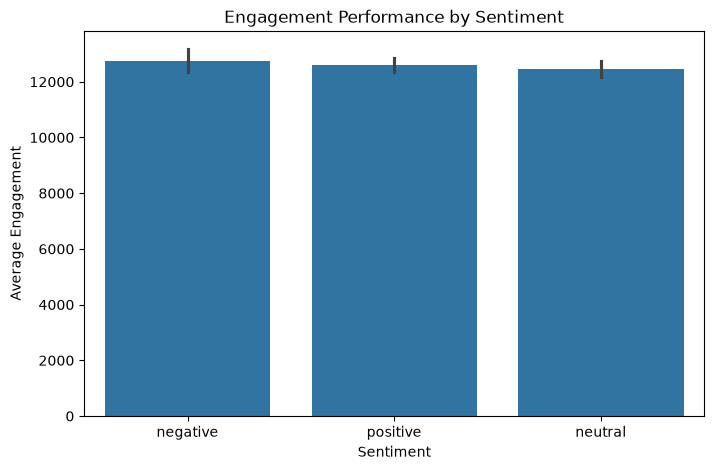

In [51]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='sentiment',
    y='engagement_score'
)

plt.xlabel('Sentiment')
plt.ylabel('Average Engagement')
plt.title('Engagement Performance by Sentiment')

plt.show()

In [50]:
negative_neutral = df[df['sentiment'].isin(['negative', 'neutral'])]

negative_neutral.groupby('sentiment').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_watch_time=('watch_time_sec', 'mean'),
    average_impressions=('impression_count', 'mean')
)

,average_likes,average_comments,average_shares,average_watch_time,average_impressions
sentiment,,,,,
negative,10211.406452,1516.584402,1007.186966,4054.639583,50191.960417
neutral,9917.785570,1529.270525,996.149966,4031.823183,49515.971185


In [48]:
df.groupby('sentiment').agg(
    total_posts=('post_id', 'count'),
    average_engagement=('engagement_score', 'mean'),
    average_engagement_rate=('engagement_rate', 'mean')
)

,total_posts,average_engagement,average_engagement_rate
sentiment,,,
negative,960,12745.962670,1.038486
neutral,1527,12459.355160,0.991170
positive,2363,12593.029963,0.954800


In [49]:
df.groupby('sentiment')['engagement_score'].mean()

sentiment
negative    12745.962670
neutral     12459.355160
positive    12593.029963
Name: engagement_score, dtype: float64